# 02 · Exploração das bases analíticas

Este notebook descreve os padrões presentes nas bases de município e de aluno, sem converter imediatamente cada resultado em uma decisão de modelagem. A interpretação e as hipóteses formais ficam no notebook seguinte.

Bases utilizadas:

- `base_analitica_municipio.parquet`, no grão `ano_alvo × id_municipio × rede`;
- `base_analitica_aluno.parquet`, no grão `ano × id_aluno`.

Para preservar memória, as análises individuais usam uma amostra estratificada de até 100 mil alunos. As estatísticas globais simples são calculadas em lotes quando necessário.


In [1]:
from pathlib import Path
import os
import gc
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42

def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists():
            return candidato
    raise FileNotFoundError("Não foi encontrada a pasta data/processed.")

PROJECT_ROOT = localizar_raiz()

# Garante que o pacote src seja localizado mesmo quando o notebook estiver
# dentro de notebooks/analysis ou for executado pelo Jupyter/NBConvert.
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Padroniza caminhos relativos usados por outros módulos do projeto.
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

from src.visualization.plot_style import (
    aplicar_estilo, salvar_figura, formatar_percentual,
    AZUL, LARANJA, CINZA, VERDE, VERMELHO, CORES_REGIAO,
)
from src.visualization.business_labels import rotulo, rotular

aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ARQ_MUN = PROCESSED / "base_analitica_municipio.parquet"
ARQ_ALU = PROCESSED / "base_analitica_aluno.parquet"
if not ARQ_MUN.exists() or not ARQ_ALU.exists():
    raise FileNotFoundError("Execute primeiro a criação das bases analíticas.")

abt_mun = pd.read_parquet(ARQ_MUN)
mun = abt_mun[abt_mun["atingiu_meta_t"].notna()].copy()
mun["atingiu"] = mun["atingiu_meta_t"].astype(int)
mun["ano_alvo"] = pd.to_numeric(mun["ano_alvo"], errors="coerce").astype("Int64")
print("Base municipal observada:", mun.shape)
print(mun.groupby("ano_alvo", observed=True).size().to_dict())


Base municipal observada: (10786, 60)
{np.int64(2024): 5347, np.int64(2025): 5439}


#####1. Distribuição dos resultados municipais


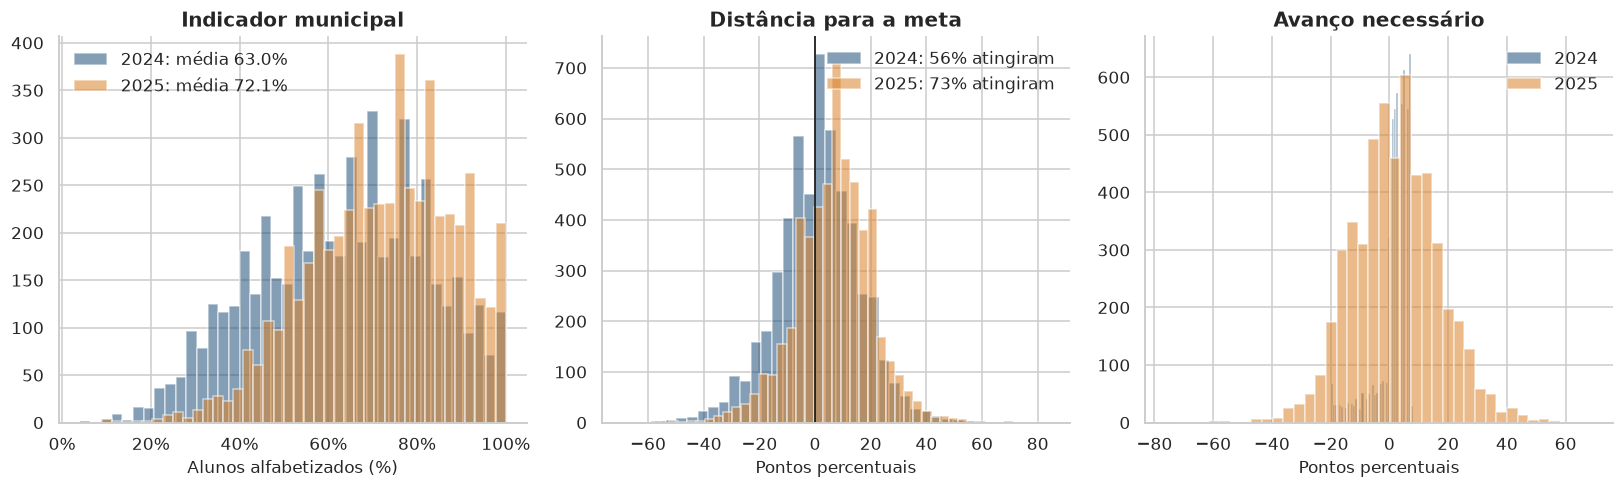

,municipios,indicador_medio,atingimento_pct,gap_mediano
ano_alvo,,,,
2024,5347,63.04,55.99,1.0
2025,5439,72.11,72.84,8.0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
anos = sorted(mun["ano_alvo"].dropna().astype(int).unique())
cores = [AZUL, LARANJA, VERDE, CINZA]
for ano, cor in zip(anos, cores):
    d = mun[mun["ano_alvo"] == ano]
    axes[0].hist(d["indicador_t"].dropna(), bins=40, alpha=.55, color=cor, label=f"{ano}: média {d['indicador_t'].mean():.1f}%")
    axes[1].hist(d["gap_meta_t"].dropna(), bins=40, alpha=.55, color=cor, label=f"{ano}: {100*d['atingiu'].mean():.0f}% atingiram")
    axes[2].hist(d["salto_necessario"].dropna(), bins=40, alpha=.55, color=cor, label=str(ano))
axes[0].set_title("Indicador municipal")
axes[0].set_xlabel("Alunos alfabetizados (%)")
axes[1].axvline(0,color="black",lw=1)
axes[1].set_title("Distância para a meta")
axes[1].set_xlabel("Pontos percentuais")
axes[2].set_title("Avanço necessário")
axes[2].set_xlabel("Pontos percentuais")
for ax in axes: ax.legend()
formatar_percentual(axes[0])
salvar_figura(fig,"02_resultados_municipais")
plt.show()

display(mun.groupby("ano_alvo").agg(
    municipios=("id_municipio","nunique"),
    indicador_medio=("indicador_t","mean"),
    atingimento_pct=("atingiu","mean"),
    gap_mediano=("gap_meta_t","median"),
).assign(atingimento_pct=lambda x:100*x["atingimento_pct"]).round(2))


#####2. Diferenças territoriais


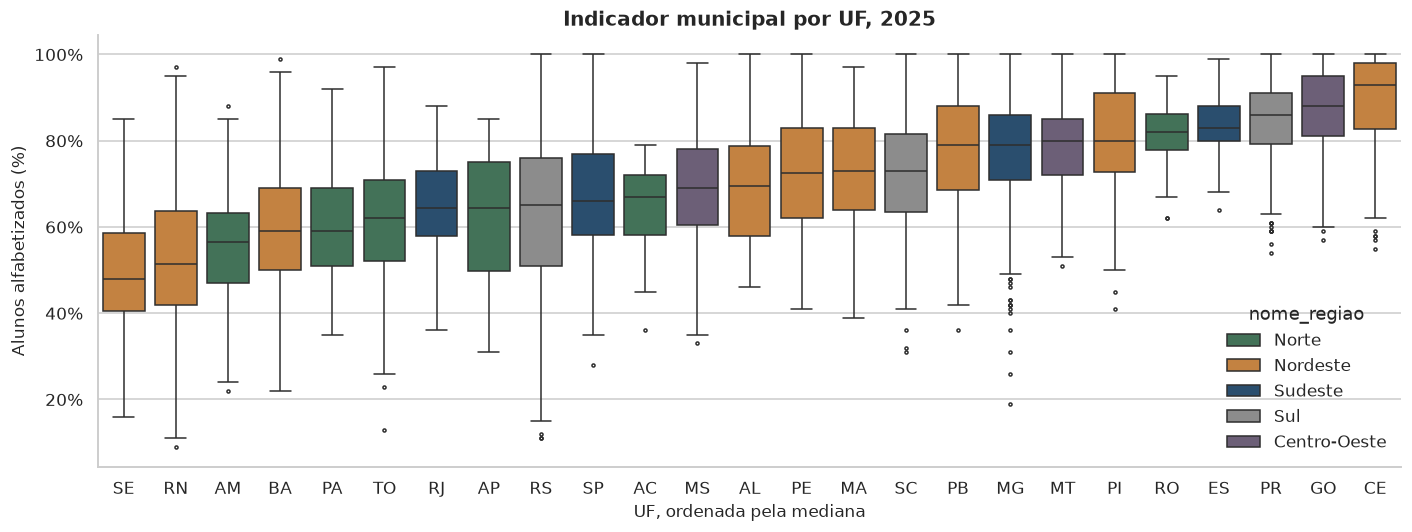

Kruskal-Wallis: H=1944.3, p=0.00e+00
Eta² aproximado da UF: 0.357


In [3]:
ano_recente = int(mun["ano_alvo"].max())
d = mun[mun["ano_alvo"] == ano_recente].copy()
ordem = d.groupby("sigla_uf")["indicador_t"].median().sort_values().index
fig, ax = plt.subplots(figsize=(13,5))
hue = "nome_regiao" if "nome_regiao" in d.columns else None
kwargs = {"palette": CORES_REGIAO, "hue": hue} if hue else {}
sns.boxplot(data=d,x="sigla_uf",y="indicador_t",order=ordem,dodge=False,fliersize=2,ax=ax,**kwargs)
ax.set_title(f"Indicador municipal por UF, {ano_recente}")
ax.set_xlabel("UF, ordenada pela mediana")
ax.set_ylabel("Alunos alfabetizados (%)")
formatar_percentual(ax,"y")
salvar_figura(fig,"02_indicador_por_uf")
plt.show()

grupos=[g["indicador_t"].dropna().values for _,g in d.groupby("sigla_uf") if g["indicador_t"].notna().sum()>1]
h,p=stats.kruskal(*grupos)
media=d["indicador_t"].mean()
ss_entre=sum(len(g)*(g.mean()-media)**2 for g in grupos)
ss_total=((d["indicador_t"]-media)**2).sum()
print(f"Kruskal-Wallis: H={h:.1f}, p={p:.2e}")
print(f"Eta² aproximado da UF: {ss_entre/ss_total:.3f}")


#####3. Contexto socioeconômico, território e economia


,variavel,coluna,spearman,p_valor,n
3,Populacao,populacao,-0.279,0.000,5439
4,Populacao em escala logaritmica,log_populacao,-0.279,0.000,5439
7,Participacao da agropecuaria no PIB (%),participacao_vab_agro_pct,0.257,0.000,5439
10,Participacao da administracao publica no PIB (%),participacao_vab_adm_publica_pct,0.215,0.000,5439
1,Alunos considerados no INSE,qtd_alunos_inse,-0.200,0.000,5428
8,Participacao da industria no PIB (%),participacao_vab_industria_pct,0.197,0.000,5439
11,Alunos no nivel socioeconomico 1 (%),pc_nivel_1,-0.151,0.000,5419
18,Alunos no nivel socioeconomico 8 (%),pc_nivel_8,0.144,0.000,3023
9,Participacao dos servicos no PIB (%),participacao_vab_servicos_pct,0.140,0.000,5439
5,Densidade demografica (hab./km²),densidade_hab_km2,-0.118,0.000,5439


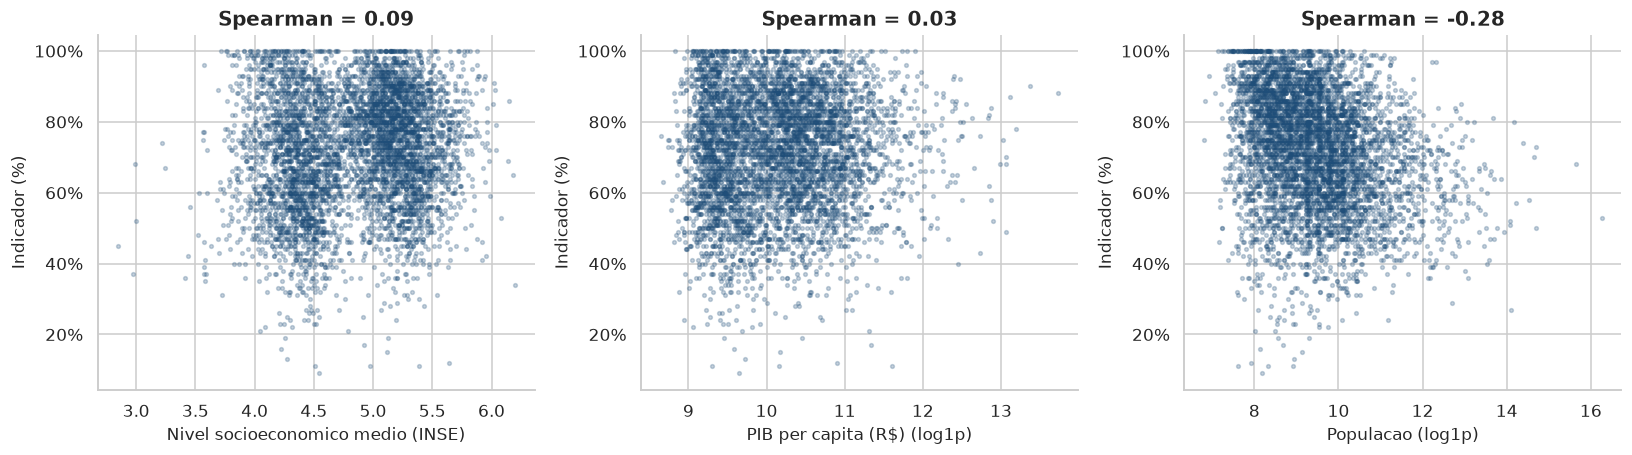

In [4]:
def spearman_seguro(df,x,y="indicador_t"):
    dd=df[[x,y]].apply(pd.to_numeric,errors="coerce").dropna()
    if len(dd)<3 or dd[x].nunique()<2: return np.nan,np.nan,len(dd)
    r,p=stats.spearmanr(dd[x],dd[y])
    return r,p,len(dd)

candidatas=[
 "media_inse","qtd_alunos_inse","pib_per_capita_reais","populacao","log_populacao",
 "densidade_hab_km2","area_km2","participacao_vab_agro_pct",
 "participacao_vab_industria_pct","participacao_vab_servicos_pct",
 "participacao_vab_adm_publica_pct",*[f"pc_nivel_{i}" for i in range(1,9)]
]
variaveis=[c for c in candidatas if c in d.columns]
linhas=[]
for v in variaveis:
    r,p,n=spearman_seguro(d,v)
    linhas.append({"variavel":rotulo(v),"coluna":v,"spearman":r,"p_valor":p,"n":n})
tab_contexto=pd.DataFrame(linhas).sort_values("spearman",key=lambda s:s.abs(),ascending=False)
display(tab_contexto.round(3))

plot_vars=[v for v in ["media_inse","pib_per_capita_reais","populacao"] if v in d.columns]
fig,axes=plt.subplots(1,len(plot_vars),figsize=(5*len(plot_vars),4.3),squeeze=False)
for ax,v in zip(axes[0],plot_vars):
    dd=d[[v,"indicador_t"]].apply(pd.to_numeric,errors="coerce").dropna()
    x=np.log1p(dd[v]) if v in {"pib_per_capita_reais","populacao"} else dd[v]
    ax.scatter(x,dd["indicador_t"],s=6,alpha=.25,color=AZUL)
    r,_,_=spearman_seguro(d,v)
    ax.set_title(f"Spearman = {r:.2f}")
    ax.set_xlabel(rotulo(v)+(" (log1p)" if v in {"pib_per_capita_reais","populacao"} else ""))
    ax.set_ylabel("Indicador (%)")
    formatar_percentual(ax,"y")
salvar_figura(fig,"02_contexto_municipal")
plt.show()


#####4. Histórico educacional e IDEB


,variavel,coluna,spearman,p_valor,n
0,Alfabetizados no ano anterior (%),indicador_t1,0.691,0.0,5323
3,Meta do ano-alvo (%),meta_t,0.569,0.0,5439
4,IDEB mais recente,ideb_ideb_observado_ultimo,0.505,0.0,5186
8,Nota de Matematica mais recente,ideb_ideb_nota_matematica_ultimo,0.480,0.0,5188
7,Nota de Portugues mais recente,ideb_ideb_nota_portugues_ultimo,0.471,0.0,5188
2,Avanco necessario para atingir a meta (p.p.),salto_necessario,-0.456,0.0,5323
5,IDEB anterior,ideb_ideb_observado_anterior,0.411,0.0,4716
10,Aprovacao nos anos iniciais (%),ideb_aprovacao_ai_pct_ultimo,0.391,0.0,5258
9,Rendimento do IDEB mais recente,ideb_ideb_rendimento_ultimo,0.391,0.0,5258
1,Participacao na avaliacao anterior (%),participacao_t1,0.274,0.0,5323


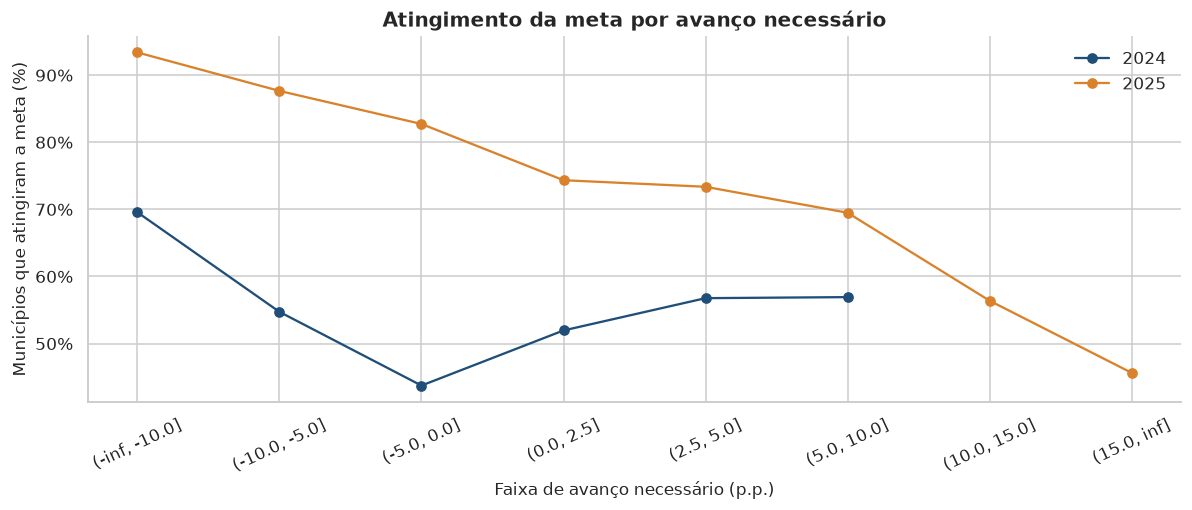

In [5]:
candidatas_hist=[
 "indicador_t1","participacao_t1","salto_necessario","meta_t",
 "ideb_ideb_observado_ultimo","ideb_ideb_observado_anterior",
 "ideb_ideb_observado_variacao","ideb_ideb_nota_portugues_ultimo",
 "ideb_ideb_nota_matematica_ultimo","ideb_ideb_rendimento_ultimo",
 "ideb_aprovacao_ai_pct_ultimo","ideb_aprovacao_1ano_pct_ultimo","ideb_aprovacao_2ano_pct_ultimo"
]
linhas=[]
for v in [c for c in candidatas_hist if c in d.columns]:
    r,p,n=spearman_seguro(d,v)
    linhas.append({"variavel":rotulo(v),"coluna":v,"spearman":r,"p_valor":p,"n":n})
tab_historico=pd.DataFrame(linhas).sort_values("spearman",key=lambda s:s.abs(),ascending=False)
display(tab_historico.round(3))

if "salto_necessario" in mun.columns:
    dd=mun[["salto_necessario","atingiu","ano_alvo"]].dropna().copy()
    dd["faixa"]=pd.cut(dd["salto_necessario"],[-np.inf,-10,-5,0,2.5,5,10,15,np.inf])
    taxa=dd.groupby(["faixa","ano_alvo"],observed=True)["atingiu"].agg(["mean","size"]).reset_index()
    taxa=taxa[taxa["size"]>=20]
    fig,ax=plt.subplots(figsize=(11,4.8))
    for ano,grupo in taxa.groupby("ano_alvo"):
        ax.plot(grupo["faixa"].astype(str),100*grupo["mean"],marker="o",label=str(int(ano)))
    ax.set_title("Atingimento da meta por avanço necessário")
    ax.set_xlabel("Faixa de avanço necessário (p.p.)")
    ax.set_ylabel("Municípios que atingiram a meta (%)")
    ax.tick_params(axis="x",rotation=25)
    ax.legend()
    formatar_percentual(ax,"y")
    salvar_figura(fig,"02_avanco_necessario")
    plt.show()


#####5. Correlação, assimetria e valores ausentes


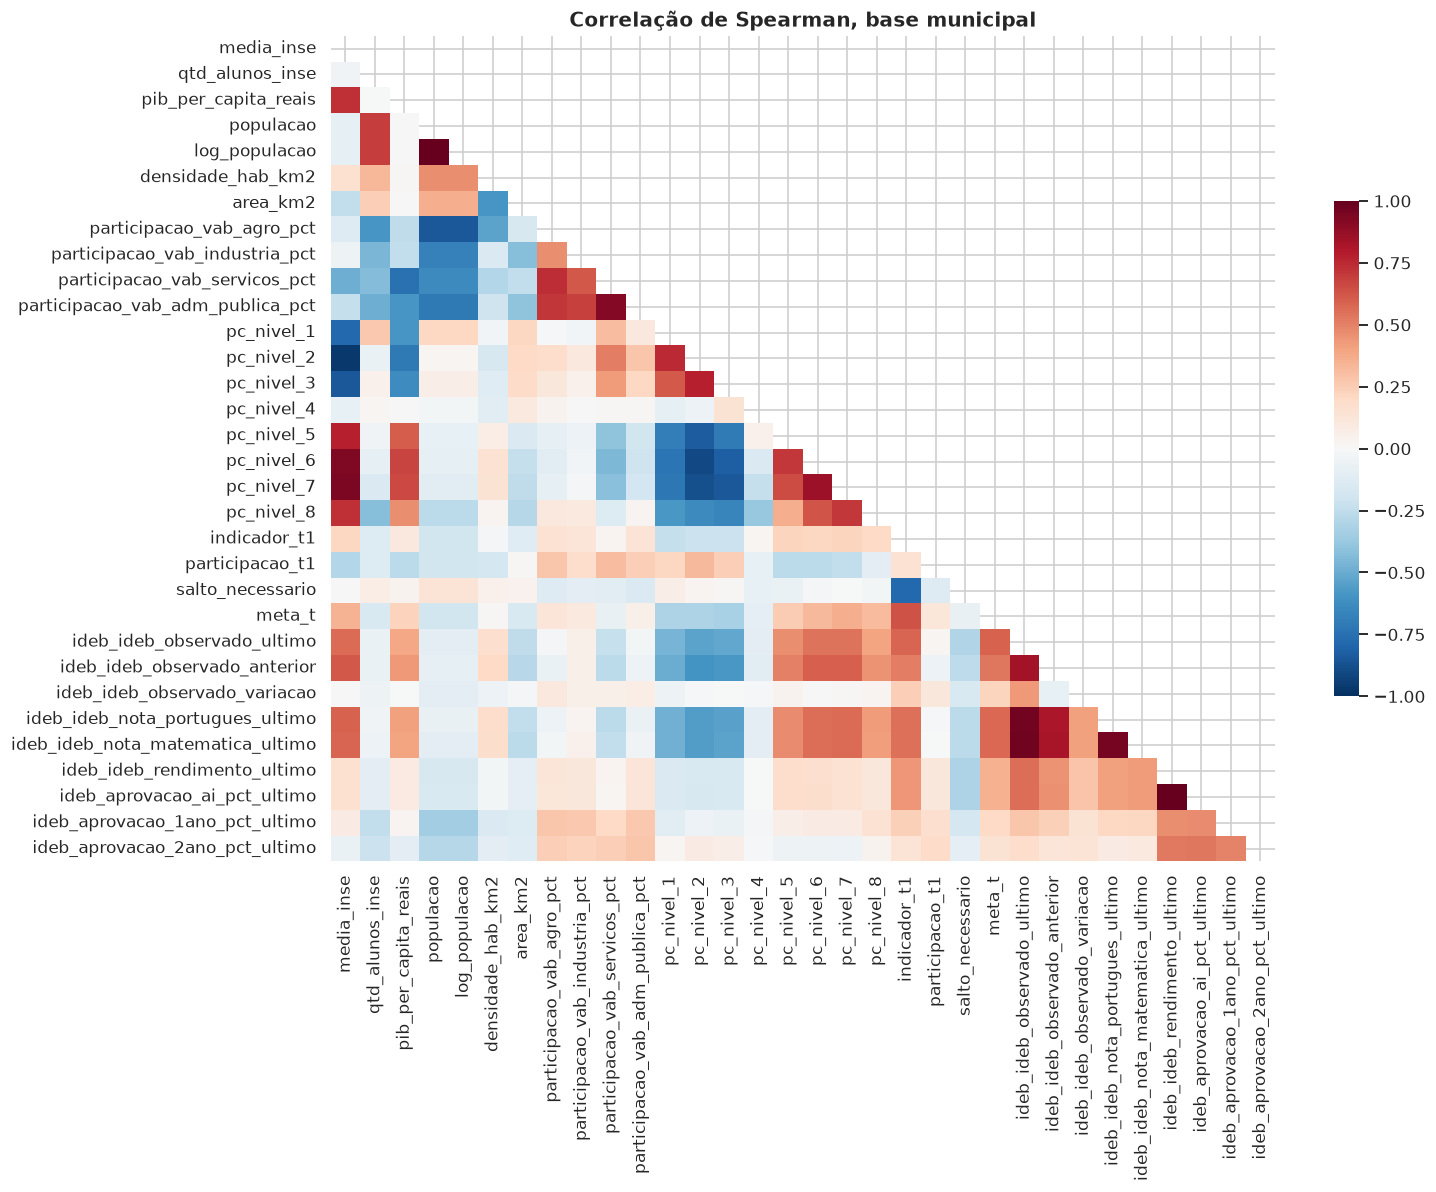

,,spearman
log_populacao,populacao,1.000000
ideb_aprovacao_ai_pct_ultimo,ideb_ideb_rendimento_ultimo,0.998520
ideb_ideb_nota_matematica_ultimo,ideb_ideb_observado_ultimo,0.974848
ideb_ideb_nota_portugues_ultimo,ideb_ideb_observado_ultimo,0.967897
pc_nivel_2,media_inse,-0.962558
ideb_ideb_nota_matematica_ultimo,ideb_ideb_nota_portugues_ultimo,0.958675
pc_nivel_7,media_inse,0.944602
pc_nivel_6,media_inse,0.931711
participacao_vab_adm_publica_pct,participacao_vab_servicos_pct,0.916969
pc_nivel_6,pc_nivel_2,-0.902712


,assimetria
populacao,38.324864
qtd_alunos_inse,26.268458
participacao_vab_industria_pct,15.040329
area_km2,13.830343
densidade_hab_km2,13.363592
pib_per_capita_reais,6.912164
pc_nivel_8,6.870045
ideb_aprovacao_1ano_pct_ultimo,-5.384307
pc_nivel_1,4.892347
ideb_aprovacao_2ano_pct_ultimo,-3.287646


,nulos_pct
pc_nivel_8,44.3
ideb_ideb_observado_variacao,14.4
ideb_ideb_observado_anterior,13.2
pc_nivel_7,8.2
pc_nivel_2,5.9
ideb_ideb_observado_ultimo,4.5
ideb_ideb_nota_portugues_ultimo,4.5
ideb_ideb_nota_matematica_ultimo,4.5
ideb_aprovacao_1ano_pct_ultimo,3.3
ideb_aprovacao_2ano_pct_ultimo,3.2


In [6]:
numericas=[c for c in dict.fromkeys(candidatas+candidatas_hist) if c in d.columns]
corr=d[numericas].corr(method="spearman")
fig,ax=plt.subplots(figsize=(14,11))
mask=np.triu(np.ones_like(corr,dtype=bool))
sns.heatmap(corr,mask=mask,cmap="RdBu_r",center=0,vmin=-1,vmax=1,ax=ax,cbar_kws={"shrink":.6})
ax.set_title("Correlação de Spearman, base municipal")
salvar_figura(fig,"02_correlacao_municipal")
plt.show()

pares=corr.where(~mask).stack().rename("spearman")
display(pares[pares.abs()>=.6].sort_values(key=lambda s:s.abs(),ascending=False).to_frame().head(30))

assimetria=d[numericas].skew(numeric_only=True).sort_values(key=lambda s:s.abs(),ascending=False)
nulos=mun[numericas].isna().mean().sort_values(ascending=False)
display(assimetria.head(15).to_frame("assimetria"))
display((100*nulos[nulos>0]).round(1).to_frame("nulos_pct"))


#####6. Exploração do grão de aluno


In [7]:
def amostrar_alunos(caminho: Path, n: int = 100_000, seed: int = SEED) -> pd.DataFrame:
    """Amostra aproximada por ano e target sem carregar o Parquet inteiro."""
    pf = pq.ParquetFile(caminho)
    total = pf.metadata.num_rows
    frac = min(1.0, n / total)
    rng = np.random.default_rng(seed)
    partes = []
    for batch in pf.iter_batches(batch_size=50_000, use_threads=False):
        lote = batch.to_pandas()
        if "alfabetizado" in lote:
            lote = lote.dropna(subset=["alfabetizado"])
        qtd = min(len(lote), max(1, int(np.ceil(len(lote) * frac * 1.2))))
        if qtd:
            idx = rng.choice(len(lote), size=qtd, replace=False)
            partes.append(lote.iloc[idx])
    amostra = pd.concat(partes, ignore_index=True)
    if len(amostra) > n:
        # novo balanceamento por ano e alvo
        estratos=[]
        for _, g in amostra.groupby(["ano", "alfabetizado"], observed=True):
            q=max(1, round(n*len(g)/len(amostra)))
            estratos.append(g.sample(n=min(q,len(g)), random_state=seed))
        amostra=pd.concat(estratos,ignore_index=True)
        if len(amostra)>n:
            amostra=amostra.sample(n=n,random_state=seed)
    return amostra.sample(frac=1,random_state=seed).reset_index(drop=True)

amostra_aluno = amostrar_alunos(ARQ_ALU, n=100_000)
print("Amostra de alunos:", amostra_aluno.shape)


Amostra de alunos: (99999, 61)


mean   size
ano  rede                   
2023 estadual   61.32   2518
     municipal  57.91  25736
2024 estadual   62.72   4547
     municipal  59.99  30236
2025 estadual   63.76   4523
     municipal  66.44  32439

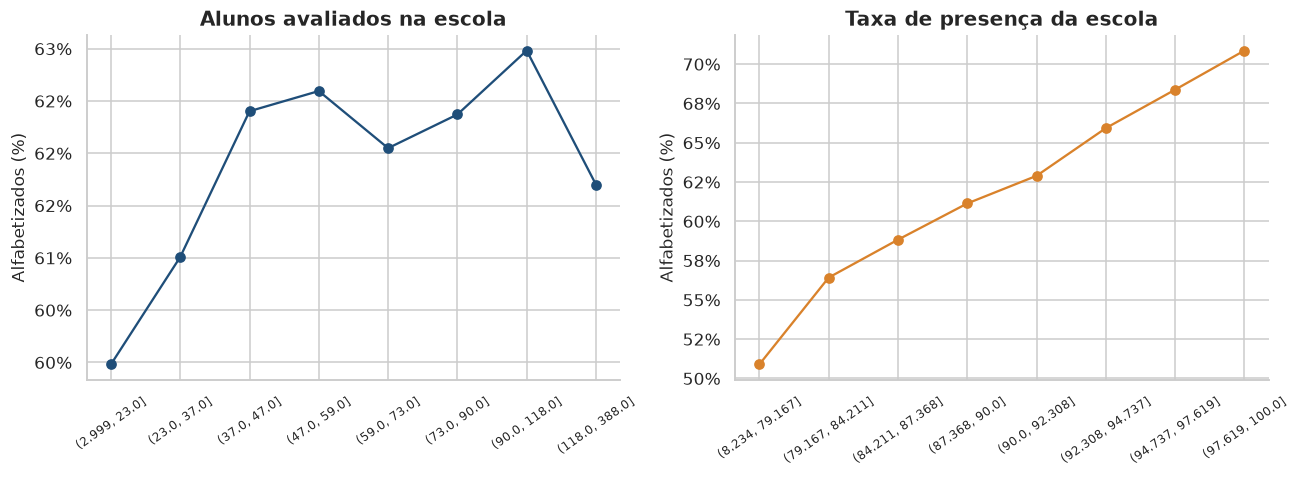

,variancia_pct_aproximada
entre municípios,18.0
entre escolas do mesmo município,47.1
entre alunos da mesma escola,34.9


In [8]:
display(amostra_aluno.groupby(["ano","rede"],observed=True)["alfabetizado"].agg(["mean","size"]).assign(mean=lambda x:100*x["mean"]).round(2))

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,v,titulo in [
    (axes[0],"escola_qtd_avaliados","Alunos avaliados na escola"),
    (axes[1],"escola_taxa_presenca","Taxa de presença da escola"),
]:
    if v not in amostra_aluno.columns: continue
    dd=amostra_aluno[[v,"alfabetizado"]].dropna().copy()
    dd["faixa"]=pd.qcut(dd[v],8,duplicates="drop")
    t=dd.groupby("faixa",observed=True)["alfabetizado"].mean()
    ax.plot(range(len(t)),100*t.values,marker="o",color=AZUL if ax is axes[0] else LARANJA)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index],rotation=35,fontsize=8)
    ax.set_title(titulo)
    ax.set_ylabel("Alfabetizados (%)")
    formatar_percentual(ax,"y")
salvar_figura(fig,"02_contexto_escolar")
plt.show()

# Decomposição aproximada na amostra do ano mais recente.
a=amostra_aluno[amostra_aluno["ano"]==amostra_aluno["ano"].max()].dropna(subset=["id_municipio","id_escola","alfabetizado"])
media_mun=a.groupby("id_municipio")["alfabetizado"].transform("mean")
media_esc=a.groupby("id_escola")["alfabetizado"].transform("mean")
decomp=pd.Series({
 "entre municípios":media_mun.var(),
 "entre escolas do mesmo município":(media_esc-media_mun).var(),
 "entre alunos da mesma escola":(a["alfabetizado"]-media_esc).var(),
})
display((100*decomp/decomp.sum()).round(1).to_frame("variancia_pct_aproximada"))


#####7. Síntese descritiva

As tabelas `tab_contexto` e `tab_historico`, os gráficos territoriais e os diagnósticos de correlação constituem a evidência descritiva. O notebook seguinte transforma essa evidência em hipóteses, testes e regras explícitas para o pipeline.


In [9]:
achados_eda=pd.concat([
    tab_contexto.assign(bloco="contexto municipal"),
    tab_historico.assign(bloco="histórico educacional"),
],ignore_index=True)
display(achados_eda.sort_values("spearman",key=lambda s:s.abs(),ascending=False).head(25))


,variavel,coluna,spearman,p_valor,n,bloco
19,Alfabetizados no ano anterior (%),indicador_t1,0.691273,0.000000e+00,5323,histórico educacional
20,Meta do ano-alvo (%),meta_t,0.569239,0.000000e+00,5439,histórico educacional
21,IDEB mais recente,ideb_ideb_observado_ultimo,0.505431,0.000000e+00,5186,histórico educacional
22,Nota de Matematica mais recente,ideb_ideb_nota_matematica_ultimo,0.479962,3.177666e-297,5188,histórico educacional
23,Nota de Portugues mais recente,ideb_ideb_nota_portugues_ultimo,0.470603,2.839651e-284,5188,histórico educacional
24,Avanco necessario para atingir a meta (p.p.),salto_necessario,-0.455613,3.521153e-271,5323,histórico educacional
25,IDEB anterior,ideb_ideb_observado_anterior,0.410992,1.136711e-191,4716,histórico educacional
26,Aprovacao nos anos iniciais (%),ideb_aprovacao_ai_pct_ultimo,0.391066,1.041549e-191,5258,histórico educacional
27,Rendimento do IDEB mais recente,ideb_ideb_rendimento_ultimo,0.390626,3.029136e-191,5258,histórico educacional
0,Populacao,populacao,-0.278827,1.087352e-97,5439,contexto municipal


#### Análise do Notebook 02 · Exploração dos Dados

#### 1. Objetivo e escopo

O notebook descreve os padrões presentes nas bases analíticas de município e aluno antes da etapa de modelagem. A exploração foi mantida separada da formulação de hipóteses, deixando as decisões formais para o notebook seguinte.

As bases utilizadas são:

- `base_analitica_municipio.parquet`, no grão `ano_alvo × id_municipio × rede`;
- `base_analitica_aluno.parquet`, no grão `ano × id_aluno`.

A exploração municipal usa **10.786 registros observados**:

- 5.347 registros no ano-alvo de 2024;
- 5.439 registros no ano-alvo de 2025.

Para preservar memória, a análise individual usa uma amostra aproximada e estratificada de **99.999 alunos**, obtida em lotes e balanceada por ano e target `alfabetizado`.

> Como a base municipal preserva a coluna `rede`, os totais representam registros de município por rede. Eles não devem ser interpretados automaticamente como quantidade de municípios únicos.

---

#### 2. Evolução dos resultados municipais

O notebook mostra melhora agregada entre 2024 e 2025. O percentual de registros municipais que atingiram a meta aumentou de aproximadamente **56,0% para 72,8%**, e a distribuição do indicador deslocou-se para níveis superiores em 2025.

##### Interpretação

O avanço é relevante, mas não deve ser atribuído diretamente a uma política específica. Entre os anos podem ter mudado:

- cobertura territorial;
- composição dos municípios e redes;
- participação dos alunos;
- instrumentos estaduais de avaliação;
- exigência das metas;
- contexto educacional e políticas implementadas.

Esse comportamento justifica um **teste temporal**, com treinamento em um período e avaliação no período seguinte, em vez de depender apenas de uma divisão aleatória da mesma base.

---

#### 3. Diferenças territoriais

As distribuições do indicador variam de forma expressiva entre as UFs. O teste de Kruskal-Wallis apresentou estatística próxima de **1.944,3**, com valor-p praticamente zero. A medida de efeito registrada foi `Eta² ≈ 0,36`.

##### Leitura adequada

O resultado sustenta que a UF contém informação preditiva relevante e deve ser considerada na modelagem.

Entretanto, não significa que a UF cause 36% do resultado. A variável reúne diferentes componentes:

- políticas estaduais;
- regime de colaboração;
- instrumentos de avaliação;
- histórico educacional;
- características econômicas e sociais;
- composição das redes.

Assim, `sigla_uf` pode ser utilizada como variável categórica, mas deve ser interpretada como um **efeito contextual agregado**, não causal.

##### Implicação para validação

O resultado sustenta duas avaliações distintas:

1. generalização para municípios novos de UFs conhecidas, com folds por município;
2. extrapolação para uma UF não vista, com leave-one-UF-out.

Esses protocolos respondem a perguntas diferentes e não devem ser confundidos.

---

#### 4. Histórico educacional 

O histórico educacional é o bloco com as associações mais fortes com o indicador municipal atual.

| Variável | Spearman |
|---|---:|
| Alfabetizados no ano anterior, `indicador_t1` | 0,691 |
| Meta do ano-alvo, `meta_t` | 0,569 |
| IDEB mais recente | 0,505 |
| Nota de Matemática mais recente | 0,480 |
| Nota de Português mais recente | 0,471 |
| Avanço necessário para atingir a meta | -0,456 |
| IDEB anterior | 0,411 |
| Aprovação nos anos iniciais | 0,391 |
| Rendimento do IDEB mais recente | 0,391 |
| Participação na avaliação anterior | 0,274 |

O percentual de alfabetizados no ano anterior é a variável isolada mais associada ao indicador atual. O IDEB, as notas de Português e Matemática e o rendimento escolar também apresentam relações relevantes.

##### Consequências para a modelagem

Os resultados sustentam:

- baseline baseado no resultado anterior;
- inclusão do histórico municipal;
- ablação do bloco de histórico;
- regularização para lidar com redundância;
- validação temporal;
- comparação do modelo com regras simples.

##### Cuidado com `meta_t`

A associação entre `meta_t` e `indicador_t` não significa que a meta produza o resultado. As metas podem ser definidas a partir da trajetória anterior do município.

Para o modelo municipal de nível, a formulação mais limpa é:

1. prever `indicador_t` sem usar a meta;
2. comparar o nível previsto com `meta_t`;
3. derivar o risco de não atingir.

Isso reduz a dependência do modelo em relação à regra administrativa da meta.

---

#### 5. Contexto socioeconômico, territorial e econômico

As associações contextuais são menores que as do histórico educacional.

| Variável | Spearman |
|---|---:|
| População | -0,279 |
| Participação da agropecuária no PIB | 0,257 |
| Participação da administração pública no PIB | 0,215 |
| Quantidade de alunos considerados no INSE | -0,200 |
| Participação da indústria no PIB | 0,197 |
| Alunos no nível socioeconômico 1 | -0,151 |
| Alunos no nível socioeconômico 8 | 0,144 |
| Participação dos serviços no PIB | 0,140 |
| Densidade demográfica | -0,118 |
| INSE médio | 0,093 |
| PIB per capita | 0,028 |

##### Interpretação

O contexto socioeconômico não deve ser descartado, pois pode contribuir:

- em interações;
- em relações não lineares;
- na diferenciação de municípios com histórico semelhante;
- na segmentação territorial;
- na explicação de diferenças residuais.

Contudo, os resultados não sustentam que renda seja o principal fator da alfabetização. O histórico e o IDEB possuem associações muito mais fortes.

A correlação negativa entre população e indicador sugere que municípios maiores tendem a apresentar indicador menor na amostra analisada. Isso não representa efeito causal. População pode funcionar como proxy de complexidade de gestão, heterogeneidade territorial ou tamanho da rede.

---

#### 6. Colinearidade

O notebook identificou vários pares altamente correlacionados.

| Par de variáveis | Spearman |
|---|---:|
| População e log da população | 1,000 |
| Aprovação nos anos iniciais e rendimento do IDEB | 0,999 |
| Nota de Matemática e IDEB | 0,975 |
| Nota de Português e IDEB | 0,968 |
| Matemática e Português | 0,959 |
| `pc_nivel_2` e INSE médio | -0,963 |
| `pc_nivel_7` e INSE médio | 0,945 |
| Administração pública e serviços no VAB | 0,917 |
| IDEB anterior e IDEB mais recente | 0,836 |
| Avanço necessário e indicador anterior | -0,783 |

##### Implicações

- modelos lineares devem utilizar regularização;
- coeficientes isolados não devem ser interpretados como efeitos puros;
- importâncias podem ser divididas entre features correlacionadas;
- importância por permutação pode subestimar variáveis redundantes;
- seleção de features deve ser validada no backtest.

##### Ajuste recomendado

`populacao` e `log_populacao` não devem entrar juntas. Como apresentam correlação perfeita, é preferível manter `log_populacao`, que também trata melhor a assimetria.

Para blocos redundantes do IDEB e do INSE, a escolha deve considerar cobertura, interpretação e desempenho fora da amostra.

---

#### 7. Assimetria

As variáveis territoriais e econômicas apresentam caudas longas.

| Variável | Assimetria |
|---|---:|
| População | 38,32 |
| Quantidade de alunos no INSE | 26,27 |
| Participação da indústria | 15,04 |
| Área municipal | 13,83 |
| Densidade demográfica | 13,36 |
| PIB per capita | 6,91 |
| `pc_nivel_8` | 6,87 |

##### Implicação para o pré-processamento

É coerente aplicar `log1p` em variáveis positivas como:

- população;
- quantidade de alunos;
- área;
- densidade;
- PIB per capita.

A transformação reduz a influência de valores extremos e melhora a geometria para modelos lineares, PCA e K-Means.

Não se deve aplicar `log1p` automaticamente a percentuais ou variáveis que possam assumir valores negativos.

---

#### 8. Valores ausentes

As maiores proporções de valores ausentes foram:

| Variável | Nulos |
|---|---:|
| `pc_nivel_8` | 44,3% |
| Variação recente do IDEB | 14,4% |
| IDEB anterior | 13,2% |
| `pc_nivel_7` | 8,2% |
| `pc_nivel_2` | 5,9% |
| IDEB mais recente | 4,5% |
| Nota de Português mais recente | 4,5% |
| Nota de Matemática mais recente | 4,5% |

A feature `pc_nivel_8` é o principal problema de cobertura, com observações válidas em apenas 3.023 dos 5.439 registros analisados.

##### Recomendações

- imputar pela mediana dentro da pipeline;
- criar indicador de ausência quando a falta do dado puder carregar informação;
- comparar o modelo com e sem `pc_nivel_8`;
- evitar interpretar a importância de variáveis com alta ausência sem considerar cobertura;
- remover features totalmente nulas no recorte de treino;
- ajustar o imputador somente no treinamento.

A ausência de 44,3% em `pc_nivel_8` justifica uma ablação explícita.

---

#### 9. Exploração no grão de aluno

A decomposição aproximada da variância no ano mais recente produziu:

| Componente | Participação aproximada |
|---|---:|
| Entre municípios | 18,0% |
| Entre escolas do mesmo município | 47,1% |
| Entre alunos da mesma escola | 34,9% |

O resultado sugere que a maior parcela da heterogeneidade capturada ocorre entre escolas do mesmo município, seguida da variação entre alunos da mesma escola.

##### Cuidado metodológico

A decomposição é descritiva e baseada em médias e variâncias da amostra. Não substitui um modelo multinível formal. A formulação recomendada é:

> Na amostra analisada, a decomposição descritiva atribuiu aproximadamente 18% da variação às diferenças entre municípios, 47,1% às diferenças entre escolas do mesmo município e 34,9% às diferenças entre alunos da mesma escola.

Esses percentuais não devem ser apresentados como efeitos causais ou componentes populacionais exatos.

##### Consequência para o modelo de aluno

Sem atributos individuais ricos, o modelo tende a aprender principalmente:

- município;
- escola;
- rede;
- UF;
- histórico educacional;
- contexto territorial.

Assim, a saída é mais apropriada para priorizar escolas e redes do que para tomar decisões individuais sobre crianças.

---

#### 10. Pontos fortes

O notebook apresenta boas práticas importantes:

- separa EDA de hipóteses formais;
- preserva o grão municipal com rede;
- utiliza Spearman para relações possivelmente não lineares;
- registra coeficiente, valor-p e tamanho da amostra;
- identifica colinearidade;
- mede assimetria e ausência;
- lê a base de alunos em lotes;
- usa amostragem estratificada com semente fixa;
- evita carregar milhões de linhas em memória;
- organiza os achados por contexto municipal, histórico educacional e grão de aluno.

---

#### 11. Pontos de cautela

#### 11.1 Valor-p não é relevância prática

Com milhares de municípios, correlações pequenas podem apresentar significância estatística. O PIB per capita, por exemplo, apresenta `rho = 0,028` e `p = 0,040`, mas a magnitude da relação é muito pequena.

A interpretação deve priorizar:

- magnitude do coeficiente;
- estabilidade entre anos;
- cobertura;
- ganho no backtest;
- contribuição após controlar as demais features.

##### 11.2 Meta não deve ser confundida com feature do fenômeno

`meta_t` está associada ao indicador, mas participa da definição operacional de atingimento. Para o modelo que prevê o nível, é mais seguro aplicá-la somente após a previsão.

##### 11.3 A amostra de alunos altera proporções naturais

A amostra é aproximadamente estratificada por ano e target. Taxas obtidas nessa amostra devem ser diferenciadas das estatísticas globais calculadas na base completa.

##### 11.4 A decomposição é aproximada

Os percentuais de 18,0%, 47,1% e 34,9% são úteis como diagnóstico, mas não substituem um modelo multinível.

##### 11.5 A cobertura das features é desigual

Coeficientes calculados com tamanhos de amostra diferentes não devem ser comparados sem cautela. `pc_nivel_8`, por exemplo, utiliza 3.023 registros, enquanto população utiliza 5.439.

---

#### 12. Diretrizes sustentadas pelos resultados

1. Manter o histórico do indicador como feature e baseline.
2. Usar UF como categórica e testar extrapolação para UF não vista.
3. Aplicar regularização nos modelos lineares.
4. Testar modelos de árvore para relações e interações não lineares.
5. Aplicar `log1p` às variáveis de porte e renda com elevada assimetria.
6. Imputar valores ausentes dentro da pipeline.
7. Usar indicadores de ausência quando apropriado.
8. Executar ablação dos blocos de histórico, IDEB e INSE.
9. Remover ou controlar features redundantes.
10. Validar por município e no tempo.
11. Aplicar a meta somente após a previsão do nível municipal.
12. Tratar o modelo de aluno como modelo contextual, não como diagnóstico individual.
13. Comparar com baselines simples, especialmente o resultado do ano anterior.

---

#### Conclusão

O resultado central do notebook é que a alfabetização municipal apresenta forte persistência histórica e heterogeneidade territorial. O indicador do ano anterior é a variável isolada mais associada ao resultado atual, com `rho = 0,691`. O IDEB e suas notas aparecem em seguida, enquanto as variáveis socioeconômicas e econômicas apresentam associações menores.

A exploração também evidencia três desafios técnicos:

- colinearidade elevada;
- forte assimetria nas variáveis territoriais;
- ausência relevante em algumas features.

No grão individual, a variação está fortemente estruturada por município e escola, o que limita a interpretação do modelo como uma ferramenta genuinamente individual.

> Em síntese, o melhor ponto de partida para prever alfabetização é o histórico educacional da rede, complementado por UF, IDEB e contexto municipal, com validação temporal, regularização e cuidado para não converter associação contextual em causalidade.
